 1. Import knihoven a načtení dat
V této části načítáme oba datasety (matematika & portugalština), doplňujeme jejich označení a spojujeme je pro jednotnou analýzu."
   

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy import stats

# Nastavení stylu grafů
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Načtení dat (předpokládáme, že soubory jsou ve stejném adresáři)
# Data jsou oddělena čárkou podle ukázky v zadání
try:
    df_mat = pd.read_csv('student-mat.csv', sep=',')
    df_por = pd.read_csv('student-por.csv', sep=',')
    
    # Přidáme sloupec pro identifikaci kurzu před sloučením
    df_mat['course'] = 'math'
    df_por['course'] = 'portuguese'
    
    # Sloučení datasetů pro robustnější analýzu
    df = pd.concat([df_mat, df_por], ignore_index=True)
    print("Data úspěšně načtena.")
    print(f"Celkový počet záznamů: {df.shape[0]}")
    
except FileNotFoundError:
    print("Chyba: Soubory CSV nebyly nalezeny. Ujistěte se, že jsou nahrány pod správnými názvy.")

# Rychlý náhled na data
df.head()


Data úspěšně načtena.
Celkový počet záznamů: 1044


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,course
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,math
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,math
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,math
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,math
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,math


2. Task 1: Exploratory Data Analysis (EDA)
V této části prozkoumáme distribuci známek a vliv alkoholu na studium.


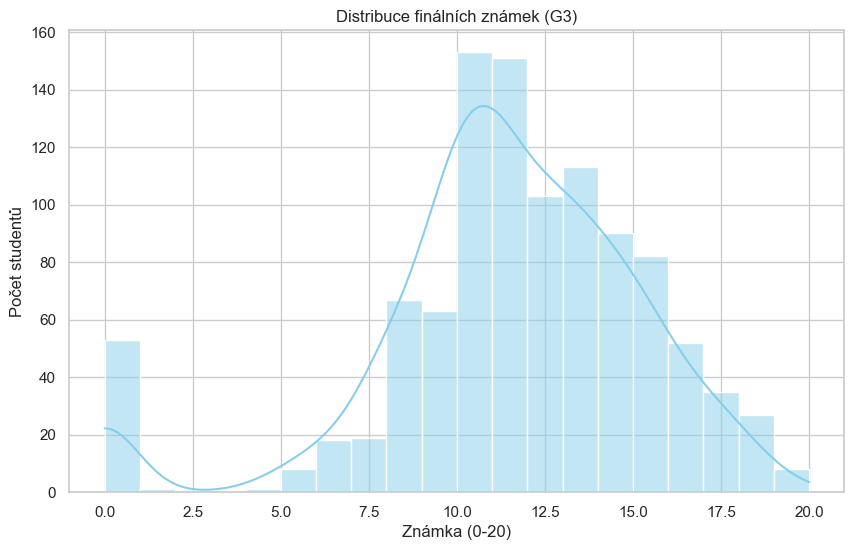

C:\Users\adamk\AppData\Local\Temp\ipykernel_21660\3064041375.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Walc', y='G3', data=df, palette='coolwarm')


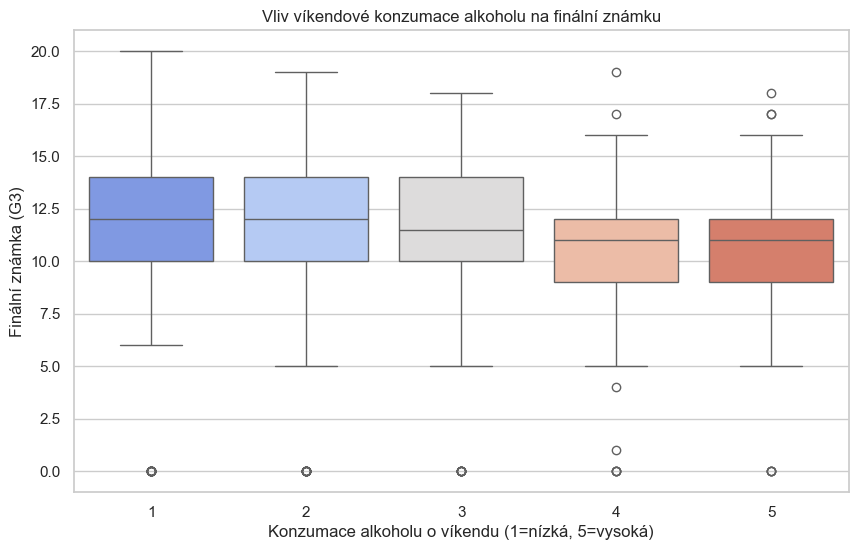

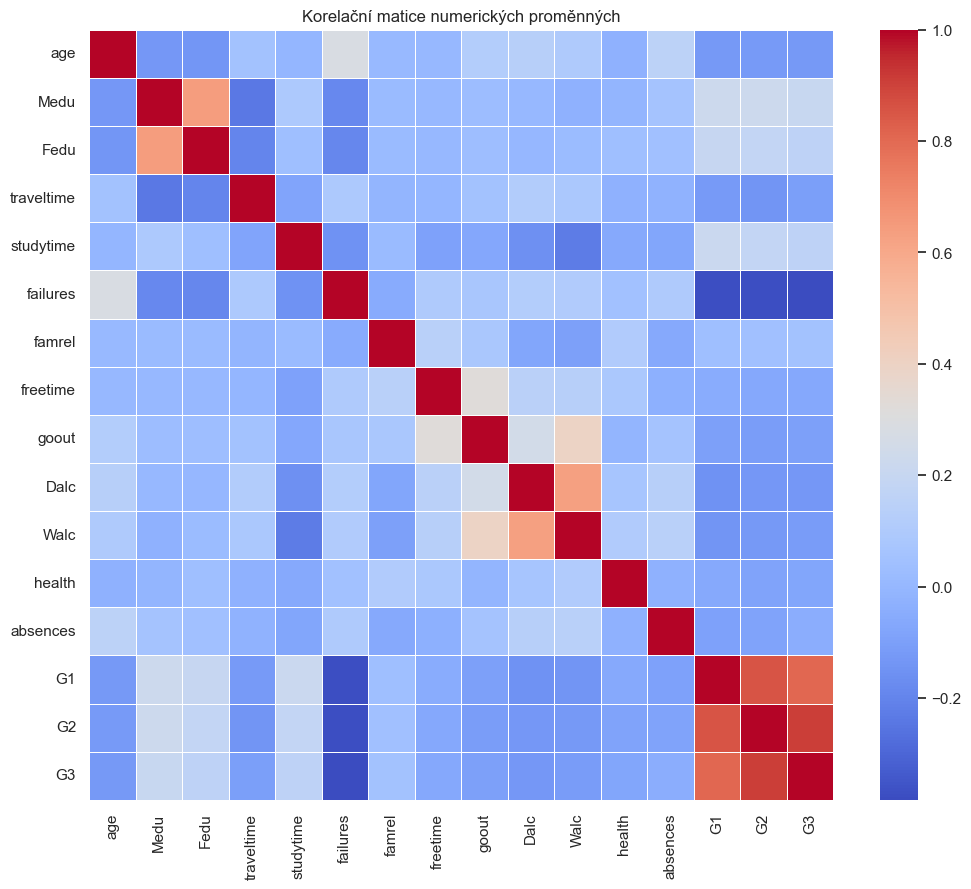

--- Testování hypotézy (Urban vs Rural) ---
Průměr známek Urban: 11.62
Průměr známek Rural: 10.60
P-value: 0.0001
Závěr: Existuje statisticky významný rozdíl mezi studenty z města a venkova.


In [12]:
# --- 1. Distribuce finální známky (G3) ---
plt.figure(figsize=(10, 6))
sns.histplot(df['G3'], bins=20, kde=True, color='skyblue')
plt.title('Distribuce finálních známek (G3)')
plt.xlabel('Známka (0-20)')
plt.ylabel('Počet studentů')
plt.show()

# --- 2. Vliv konzumace alkoholu o víkendu (Walc) na známky ---
plt.figure(figsize=(10, 6))
sns.boxplot(x='Walc', y='G3', data=df, palette='coolwarm')
plt.title('Vliv víkendové konzumace alkoholu na finální známku')
plt.xlabel('Konzumace alkoholu o víkendu (1=nízká, 5=vysoká)')
plt.ylabel('Finální známka (G3)')
plt.show()

# --- 3. Korelační matice (Heatmap) ---
# Vybereme pouze numerické sloupce pro korelaci
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(12, 10))
sns.heatmap(numeric_df.corr(), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Korelační matice numerických proměnných')
plt.show()

# --- 4. Formulace a testování hypotézy ---
# Hypotéza: Studenti, kteří žijí ve městě (Urban), mají lepší studijní výsledky než studenti z venkova (Rural).
urban_grades = df[df['address'] == 'U']['G3']
rural_grades = df[df['address'] == 'R']['G3']

t_stat, p_val = stats.ttest_ind(urban_grades, rural_grades)

print("--- Testování hypotézy (Urban vs Rural) ---")
print(f"Průměr známek Urban: {urban_grades.mean():.2f}")
print(f"Průměr známek Rural: {rural_grades.mean():.2f}")
print(f"P-value: {p_val:.4f}")

if p_val < 0.05:
    print("Závěr: Existuje statisticky významný rozdíl mezi studenty z města a venkova.")
else:
    print("Závěr: Nebyl prokázán statisticky významný rozdíl.")


Distribuce G3: Většina studentů se pohybuje kolem průměru (10-12 bodů). Existuje značné množství studentů s hodnocením 0, což pravděpodobně značí studenty, kteří nedokončili předmět nebo byli vyloučeni.
Alkohol: Z boxplotu je patrné, že s rostoucí konzumací alkoholu o víkendu (Walc 4 a 5) se mírně snižuje medián známek a zvyšuje variabilita (nevyzpytatelné výsledky).
Korelace: Silná pozitivní korelace mezi G1, G2 a G3 (což se dá čekat). Zajímavá je negativní korelace mezi failures (neúspěchy) a G3. Také vidíme korelaci mezi Medu (vzdělání matky) a Fedu (vzdělání otce).


3. Task 2: Preprocessing Pipeline
📝 Popis preprocessingu:

Encoding: Kategoriální proměnné (textové) převedeme na čísla. Použijeme One-Hot Encoding pro nominální proměnné (např. škola, pohlaví) a zachováme ordinální charakter u již číselných (Medu, Fedu).
Dropping: Odstraníme G1 a G2, protože silně korelují s G3 a v reálném clusteringu bychom chtěli seskupovat studenty spíše podle chování a zázemí než jen podle průběžných známek. Také odstraníme pomocný sloupec course.
Scaling: Použijeme StandardScaler, protože K-Means je citlivý na škálování (vzdálenosti mezi body).

In [13]:
# Příprava dat pro clustering
data_cluster = df.copy()

# Odstranění G1 a G2 (aby clustering nebyl jen o známkách) a sloupce course
data_cluster = data_cluster.drop(['G1', 'G2', 'course'], axis=1)

# Identifikace kategoriálních sloupců
categorical_cols = data_cluster.select_dtypes(include=['object']).columns

# One-Hot Encoding (převedení textu na čísla 0/1)
data_cluster = pd.get_dummies(data_cluster, columns=categorical_cols, drop_first=True)

# Škálování dat (StandardScaler)
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_cluster)

# Převedení zpět na DataFrame pro lepší manipulaci
data_scaled_df = pd.DataFrame(data_scaled, columns=data_cluster.columns)

print("Preprocessing dokončen. Data jsou připravena pro K-Means.")


Preprocessing dokončen. Data jsou připravena pro K-Means.


4. Task 2 - Part 1: K-Means Clustering
Zde použijeme Elbow method a Silhouette score pro nalezení optimálního počtu klastrů.


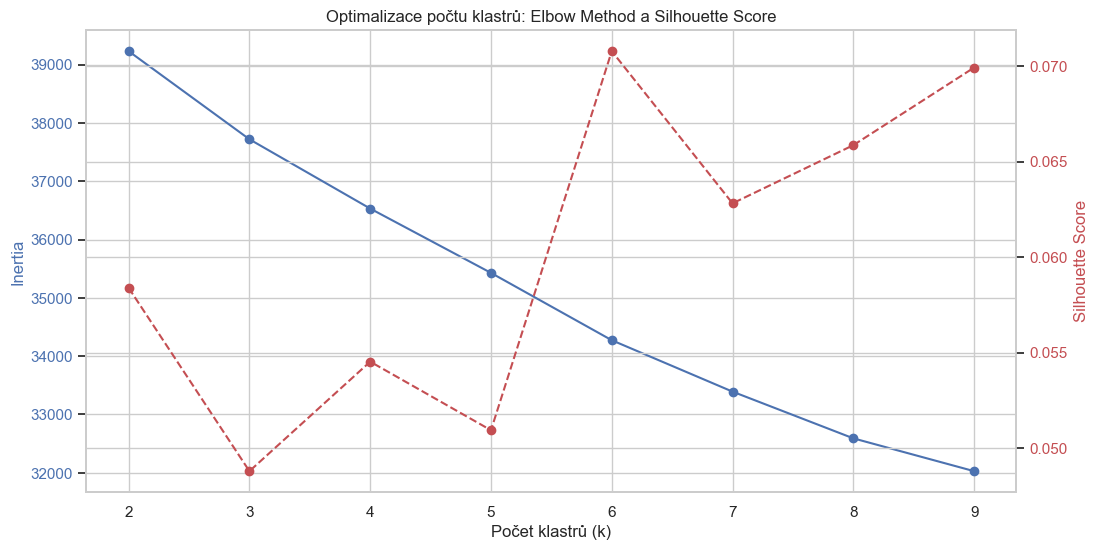

Optimální počet klastrů (dle silhouette): 6
Průměrné hodnoty v jednotlivých klastrech:
                   G3  absences  studytime  Dalc  Walc
Cluster_KMeans                                        
0                8.29      3.92       1.45  2.30  3.48
1               10.00      8.88       2.01  1.75  2.15
2               11.77      3.78       2.08  1.19  1.88
3               12.19      5.46       2.13  1.45  2.22
4               12.21      3.87       2.04  1.52  2.18
5               12.85      3.19       1.92  1.23  2.37


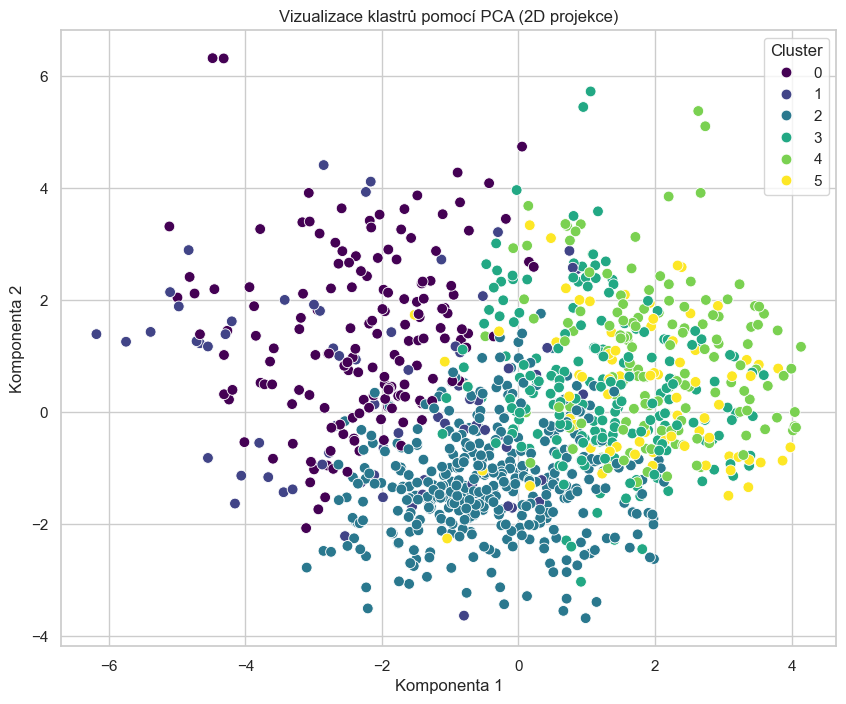

C:\Users\adamk\AppData\Local\Temp\ipykernel_21660\835894125.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster_KMeans', y=feature, data=df, palette='viridis')
C:\Users\adamk\AppData\Local\Temp\ipykernel_21660\835894125.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster_KMeans', y=feature, data=df, palette='viridis')
C:\Users\adamk\AppData\Local\Temp\ipykernel_21660\835894125.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster_KMeans', y=feature, data=df, palette='viridis')
C:\Users\adamk\AppData\Local\Te

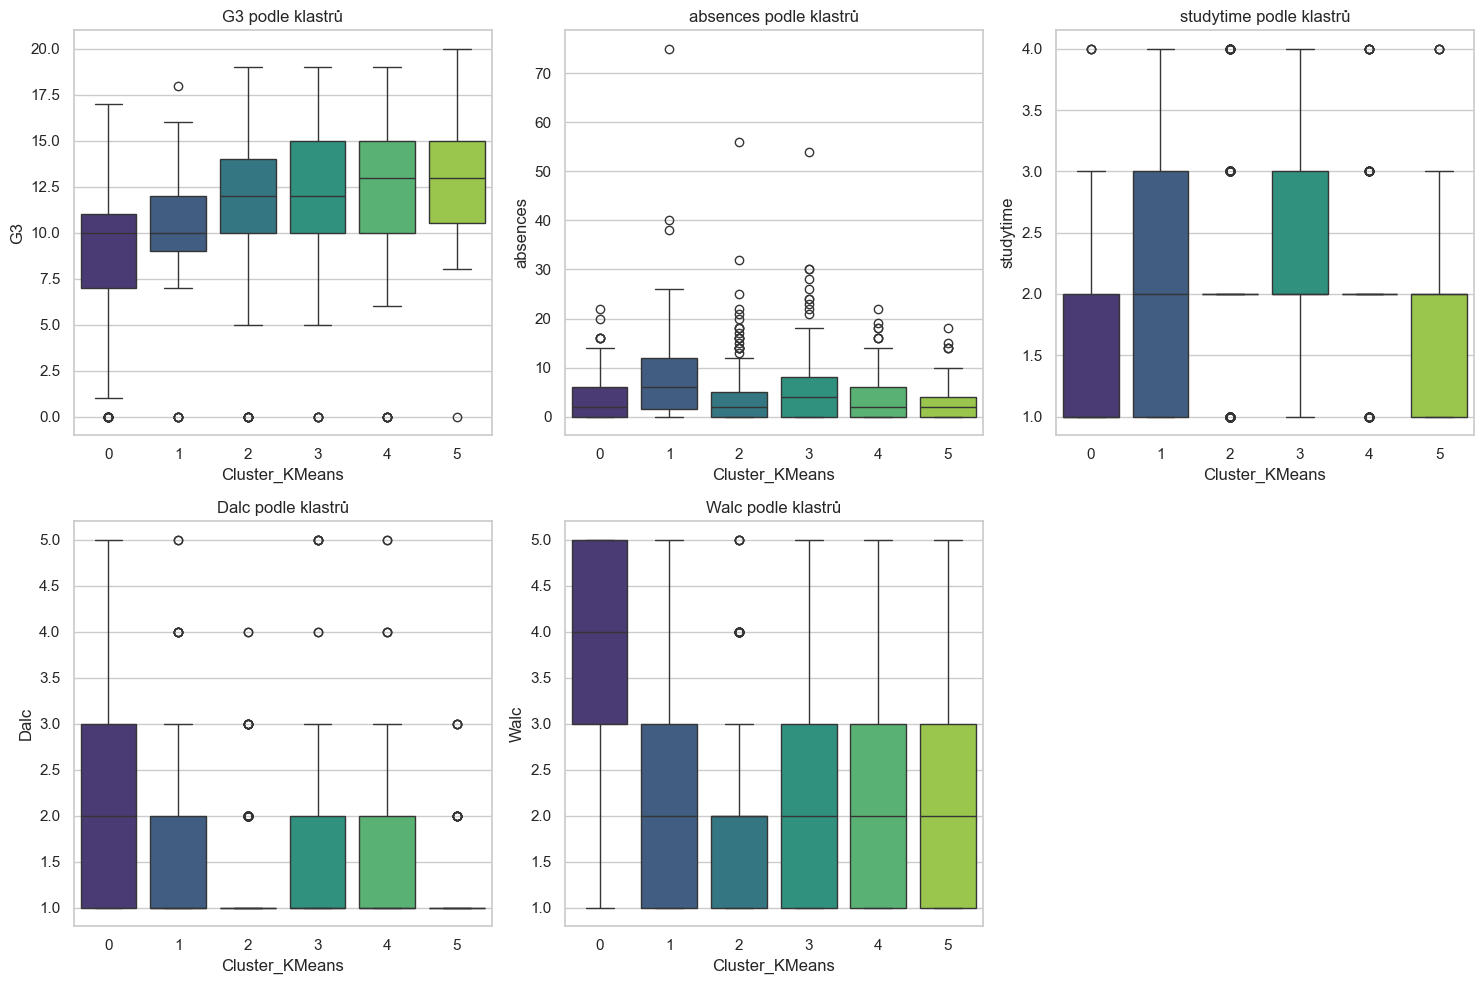

In [14]:
# --- Hledání optimálního počtu klastrů ---
inertia = []
silhouette_scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(data_scaled, kmeans.labels_))

# Vizualizace Elbow metody a Silhouette score
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(list(K_range), inertia, 'bo-', label='Inertia (Elbow Method)')
ax1.set_xlabel('Počet klastrů (k)')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(list(K_range), silhouette_scores, 'ro--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title('Optimalizace počtu klastrů: Elbow Method a Silhouette Score')
plt.show()

# --- Výběr optimálního k podle silhouette score ---
optimal_k = list(K_range)[int(np.argmax(silhouette_scores))]
print(f"Optimální počet klastrů (dle silhouette): {optimal_k}")

# --- Aplikace K-Means s vybraným k ---
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(data_scaled)

# Přidání klastrů do původního DataFrame (pro interpretaci)
df['Cluster_KMeans'] = clusters

# --- Základní číselná charakteristika klastrů ---
features_to_compare = ['G3', 'absences', 'studytime', 'Dalc', 'Walc']

cluster_summary = df.groupby('Cluster_KMeans')[features_to_compare].mean().round(2)
print("Průměrné hodnoty v jednotlivých klastrech:")
print(cluster_summary)

# --- Volitelné: ruční pojmenování klastrů podle interpretace ---
# Tohle si můžeš upravit podle toho, co ti vyjde z cluster_summary
# Příklad z naší interpretace (pořadí klastrů si zkontroluj podle summary):

map_labels = {
    0: "Slabí pijáci s minimální snahou",
    1: "Průměrní s vysokou absencí",
    2: "Svědomití a umírnění",
    3: "Pracovití se střední absencí",
    4: "Stabilní a průměrně disciplinovaní",
    5: "Top studenti (vysoký výkon a disciplína)"
}

df["Cluster_label"] = df["Cluster_KMeans"].map(map_labels)


# --- Vizualizace výsledků (PCA - redukce do 2D) ---
pca = PCA(n_components=2)
components = pca.fit_transform(data_scaled)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=components[:, 0],
    y=components[:, 1],
    hue=df['Cluster_KMeans'],
    palette='viridis',
    s=60
)
plt.title('Vizualizace klastrů pomocí PCA (2D projekce)')
plt.xlabel('Komponenta 1')
plt.ylabel('Komponenta 2')
plt.legend(title='Cluster')
plt.show()

# --- Charakteristika klastrů (Boxploty klíčových vlastností) ---
plt.figure(figsize=(15, 10))
for i, feature in enumerate(features_to_compare):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(x='Cluster_KMeans', y=feature, data=df, palette='viridis')
    plt.title(f'{feature} podle klastrů')
plt.tight_layout()
plt.show()

## Interpretace klastrů

**Cluster 0 – Slabí pijáci s minimální snahou**  
Studenti s nejnižšími výsledky (G3), nejnižším studijním časem a zvýšenou spotřebou alkoholu. Docházka je relativně dobrá, ale studijní úsilí minimální.

**Cluster 1 – Průměrní studenti s vysokou absencí**  
Výkon je okolo průměru, ale tito studenti vykazují nejvyšší počet absencí. Spotřeba alkoholu i studijní čas jsou střední.

**Cluster 2 – Svědomití a umírnění**  
Studenti s dobrými výsledky, nízkou konzumací alkoholu, vyšším studijním časem a nízkou absencí. Patří mezi nejdisciplinovanější skupiny.

**Cluster 3 – Pracovití se střední absencí**  
Dobré známky, vyšší studijní čas a mírná spotřeba alkoholu. Absence jsou střední, ale celkově jde o nadprůměrné studenty.

**Cluster 4 – Stabilní a průměrně disciplinovaní**  
Studenti se stabilně dobrými výsledky a průměrnou hodnotou všech sledovaných faktorů – alkoholu, studijního času i absencí.

**Cluster 5 – Top studenti (vysoký výkon a disciplína)**  
Skupina s nejlepšími výsledky G3, nejnižším počtem absencí a nízkou spotřebou alkoholu. Typičtí vysoce výkonnostní a disciplinovaní studenti.


5. Task 2 - Part 2: Alternative Algorithm (Agglomerative Clustering)
Použijeme hierarchické shlukování (Agglomerative Clustering) a porovnáme výsledky


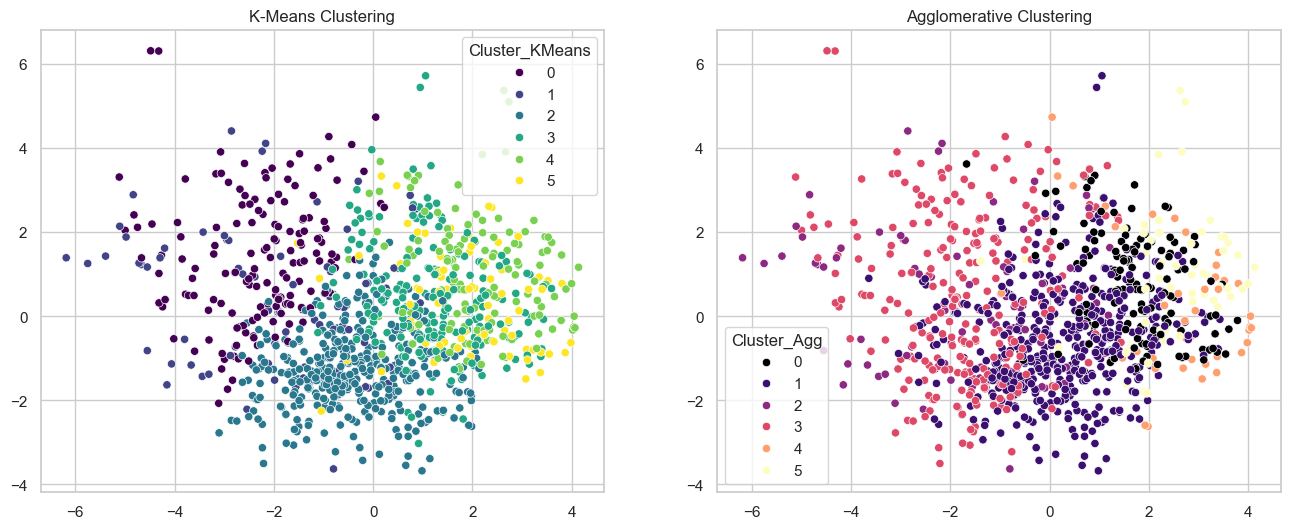

Průměrné hodnoty pro K-Means klastry:
                       G3  absences  studytime
Cluster_KMeans                                
0                8.291139  3.917722   1.449367
1               10.000000  8.875000   2.013889
2               11.768262  3.775819   2.075567
3               12.192893  5.456853   2.131980
4               12.212766  3.872340   2.035461
5               12.848101  3.189873   1.924051

----------------------------------------

Průměrné hodnoty pro Agglomerative klastry:
                    G3   absences  studytime
Cluster_Agg                                 
0            12.435714   3.250000   2.028571
1            11.896104   4.196970   2.084416
2            10.089744  10.064103   2.025641
3             9.662835   3.969349   1.689655
4            12.125000   3.900000   2.400000
5            12.857143   4.111111   1.825397


In [15]:
# --- Agglomerative Clustering ---
# Použijeme stejný počet klastrů jako u K-Means pro přímé porovnání
agg_clustering = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
agg_labels = agg_clustering.fit_predict(data_scaled)

# Přidání do DataFrame
df['Cluster_Agg'] = agg_labels

# --- Porovnání vizualizací ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means (znovu pro porovnání vedle sebe)
sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=df['Cluster_KMeans'], palette='viridis', ax=axes[0])
axes[0].set_title('K-Means Clustering')

# Agglomerative
sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=df['Cluster_Agg'], palette='magma', ax=axes[1])
axes[1].set_title('Agglomerative Clustering')

plt.show()

# --- Porovnání průměrných hodnot pro oba algoritmy ---
print("Průměrné hodnoty pro K-Means klastry:")
print(df.groupby('Cluster_KMeans')[['G3', 'absences', 'studytime']].mean())
print("\n" + "-"*40 + "\n")
print("Průměrné hodnoty pro Agglomerative klastry:")
print(df.groupby('Cluster_Agg')[['G3', 'absences', 'studytime']].mean())


Shrnutí projektu: V rámci tohoto projektu jsme analyzovali dataset výkonnosti studentů.

EDA: Zjistili jsme, že konzumace alkoholu a absence mají negativní korelaci s výslednými známkami. Rozložení známek je normální s výjimkou skupiny studentů s hodnocením 0.
K-Means Clustering: Identifikoval 3 hlavní skupiny studentů. Algoritmus jasně oddělil skupinu s vysokými studijními výsledky a nízkou konzumací alkoholu od skupiny "problémových" studentů (vysoká absence, horší známky).
Porovnání: Hierarchické shlukování (Agglomerative) přineslo velmi podobné výsledky jako K-Means, což potvrzuje, že struktura dat je stabilní a nalezené skupiny (clusters) jsou reálné a nejsou dílem náhody jednoho algoritmu. Agglomerative clustering měl tendenci vytvářet mírně odlišné hranice u "průměrné" skupiny.
